# Cluster stability

How much of the clustering survives resampling. Every panel here reads
`output_data/stability/` and `output_data/clusters/` — nothing is recomputed, and
`mario.scenes` is never opened.

Three questions, in order:

1. **What was the old corpus?** (`audit.json`) — the stored partitions had no recorded
   parameters and were not all made alike. The audit recovers them and scores them.
2. **Which parameters should we use?** (`*_sweep.json`, `selected_params.json`) — a
   12-point grid scored by how much of each scene lands in a cluster that reproduces.
3. **How good is the result?** (`*_clusters.json`) — per-cluster Jaccard and per-trace
   consensus confidence from the bagged run.

In [1]:
import json
import re
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_DATA_DIR = Path(os.environ["SOURCE_DATA_DIR"])
OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])

STABILITY_DIR = OUTPUT_DATA_DIR / "stability"
CLUSTERS_DIR = OUTPUT_DATA_DIR / "clusters"

# Hennig (2007) reference bands for the resampling Jaccard.
DISSOLVED, STABLE = 0.60, 0.85

In [2]:
import sys
sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.trace_plots import STABILITY_STOPS, plot_scene_clusters, default_background_dir
from matplotlib.colors import LinearSegmentedColormap

STABILITY_CMAP = LinearSegmentedColormap.from_list("stability", STABILITY_STOPS)

## 1. The audit — what the previous corpus actually was

In [3]:
audit_path = STABILITY_DIR / "audit.json"
audit = json.loads(audit_path.read_text())["scenes"] if audit_path.exists() else {}

if not audit:
    print("No audit.json — run `invoke run-cluster-audit`. Skipping section 1.")
else:
    rows = [{"scene": s, **{k: v[k] for k in ("n", "k", "noise_frac", "stable_share", "recovery_ari")},
             "mcs": (v["recovered"] or {}).get("min_cluster_size"),
             "min_samples": (v["recovered"] or {}).get("min_samples"),
             "eps": (v["recovered"] or {}).get("cluster_selection_epsilon")}
            for s, v in audit.items()]
    audit_df = pd.DataFrame(rows)
    print(f"{len(audit_df)} scenes audited; "
          f"{(audit_df.recovery_ari >= 0.999).sum()} had their parameters recovered exactly.")
    display(audit_df.groupby(["mcs", "min_samples", "eps"], dropna=False)
                    .size().sort_values(ascending=False).rename("scenes").to_frame())

308 scenes audited; 308 had their parameters recovered exactly.


scenes
mcs min_samples eps         
10  5.0         0.0      144
5   NaN         0.0       91
10  NaN         0.0       23
    3.0         0.0       19
5   NaN         25.0       6
                5.0        6
                50.0       5
                40.0       4
                20.0       3
                30.0       3
                10.0       1
    3.0         0.0        1
10  3.0         25.0       1
                10.0       1

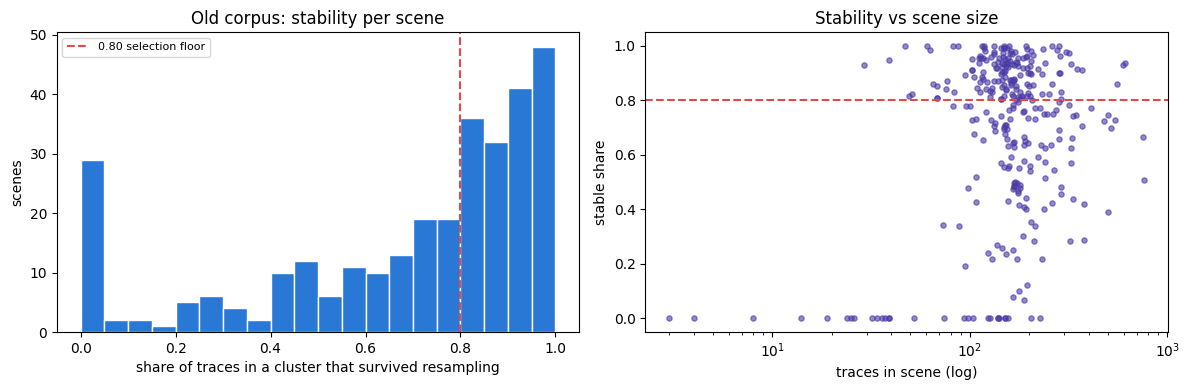

In [4]:
if audit:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(audit_df.stable_share, bins=20, color="#2a78d6", edgecolor="white")
    axes[0].axvline(0.80, color="#e34948", ls="--", lw=1.5, label="0.80 selection floor")
    axes[0].set_xlabel("share of traces in a cluster that survived resampling")
    axes[0].set_ylabel("scenes")
    axes[0].set_title("Old corpus: stability per scene")
    axes[0].legend(fontsize=8)

    # Size does not predict the failures — worth showing rather than asserting.
    axes[1].scatter(audit_df.n, audit_df.stable_share, s=14, alpha=0.6, color="#4a3aa7")
    axes[1].axhline(0.80, color="#e34948", ls="--", lw=1.5)
    axes[1].set_xscale("log")
    axes[1].set_xlabel("traces in scene (log)")
    axes[1].set_ylabel("stable share")
    axes[1].set_title("Stability vs scene size")

    fig.tight_layout()
    fig.savefig(OUTPUT_DATA_DIR / "clusters" / "figure_stability_audit.png", dpi=150,
                bbox_inches="tight")
    plt.show()

## 2. The parameter sweep

In [5]:
sweeps = sorted(STABILITY_DIR.glob("*_sweep.json"))
sweep_rows = []
for f in sweeps:
    payload = json.loads(f.read_text())
    for r in payload.get("rows", []):
        sweep_rows.append({"scene": payload["scene"], **r})
sweep_df = pd.DataFrame(sweep_rows)

selected_path = STABILITY_DIR / "selected_params.json"
selected = json.loads(selected_path.read_text()) if selected_path.exists() else None
if selected:
    print("selected:", selected["selected"], "| cleared floor:", selected["cleared_floor"])

selected: {'min_cluster_size': 5, 'cluster_selection_epsilon': 20.0} | cleared floor: True


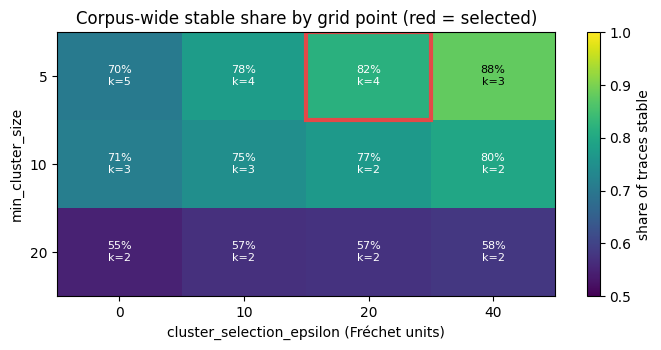

In [6]:
if not sweep_df.empty:
    # Trace-weighted, matching select_global_params: stable_share is already a
    # per-trace proportion, so weighting by n composes it corpus-wide.
    agg = (sweep_df.assign(stable_n=sweep_df.stable_share * sweep_df.n)
                   .groupby(["min_cluster_size", "epsilon"])
                   .agg(stable=("stable_n", "sum"), n=("n", "sum"), k=("k", "median")))
    agg["stable_share"] = agg.stable / agg.n
    grid = agg.stable_share.unstack()
    kgrid = agg.k.unstack()

    fig, ax = plt.subplots(figsize=(7, 3.6))
    im = ax.imshow(grid.values, cmap="viridis", aspect="auto", vmin=0.5, vmax=1.0)
    ax.set_xticks(range(len(grid.columns)), [f"{c:.0f}" for c in grid.columns])
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel("cluster_selection_epsilon (Fréchet units)")
    ax.set_ylabel("min_cluster_size")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.values[i, j]:.0%}\nk={kgrid.values[i, j]:.0f}",
                    ha="center", va="center", fontsize=8,
                    color="white" if grid.values[i, j] < 0.85 else "black")
    if selected:
        sj = list(grid.columns).index(selected["selected"]["cluster_selection_epsilon"])
        si = list(grid.index).index(selected["selected"]["min_cluster_size"])
        ax.add_patch(plt.Rectangle((sj - .5, si - .5), 1, 1, fill=False,
                                   edgecolor="#e34948", lw=3))
    ax.set_title("Corpus-wide stable share by grid point (red = selected)")
    fig.colorbar(im, ax=ax, label="share of traces stable")
    fig.tight_layout()
    fig.savefig(OUTPUT_DATA_DIR / "clusters" / "figure_stability_sweep.png", dpi=150,
                bbox_inches="tight")
    plt.show()

The selection rule is *most resolution above a floor*, not *most stability*: the
highest-scoring cell collapses scenes toward k=2, so the rule takes the largest median k
whose stable share still clears 0.80.

## 3. The bagged result

In [7]:
cluster_files = sorted(CLUSTERS_DIR.glob("*_clusters.json"))
per_cluster, per_scene = [], []
for f in cluster_files:
    d = json.loads(f.read_text())
    stab = d.get("stability")
    if not stab:
        continue
    per_scene.append({"scene": d["scene"], "n": len(d["labels"]),
                      "k": len({l for l in d["labels"] if l != -1}),
                      "stable_share": stab["stable_share"],
                      "noise_frac": stab["noise_frac"],
                      "k_rep_mean": stab["k_replicates"]["mean"],
                      "k_rep_sd": stab["k_replicates"]["sd"],
                      "min_co_sampled": stab["min_co_sampled"]})
    for label, j in stab["per_cluster"].items():
        size = sum(1 for l in d["labels"] if l == int(label))
        per_cluster.append({"scene": d["scene"], "cluster": int(label),
                            "size": size, "jaccard": j})

scene_df = pd.DataFrame(per_scene)
cluster_df = pd.DataFrame(per_cluster)
print(f"{len(scene_df)} scenes with stability, {len(cluster_df)} clusters total")
if not scene_df.empty:
    print(f"median stable share {scene_df.stable_share.median():.0%}; "
          f"smallest co-sampled pair anywhere: {scene_df.min_co_sampled.min()}")

308 scenes with stability, 1326 clusters total
median stable share 88%; smallest co-sampled pair anywhere: 56


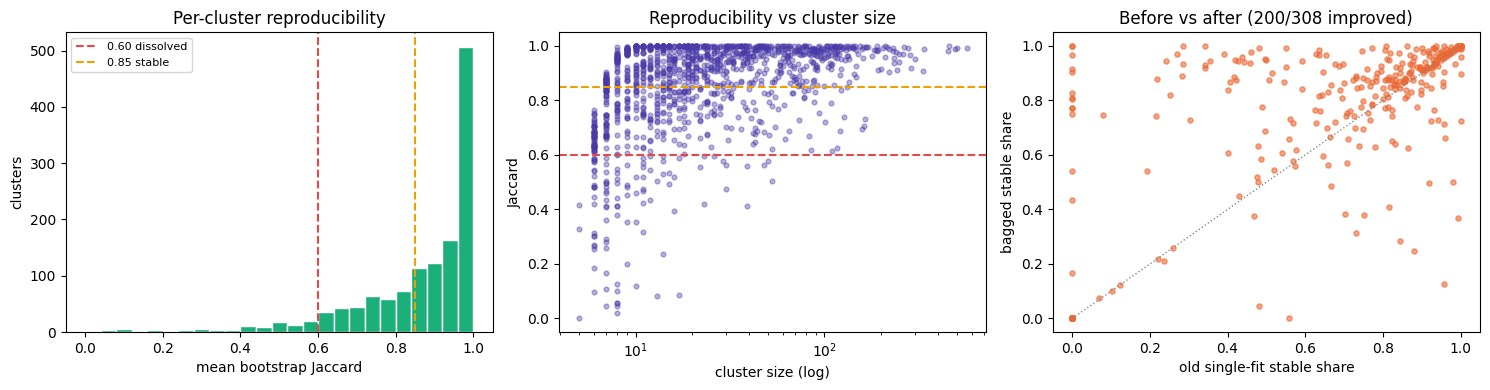

In [8]:
if not cluster_df.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].hist(cluster_df.jaccard, bins=25, color="#1baf7a", edgecolor="white")
    for x, c, lbl in ((DISSOLVED, "#e34948", "0.60 dissolved"), (STABLE, "#eda100", "0.85 stable")):
        axes[0].axvline(x, color=c, ls="--", lw=1.5, label=lbl)
    axes[0].set_xlabel("mean bootstrap Jaccard")
    axes[0].set_ylabel("clusters")
    axes[0].set_title("Per-cluster reproducibility")
    axes[0].legend(fontsize=8)

    # Small clusters are the ones that dissolve — the reason min_cluster_size and
    # the stability floor interact.
    axes[1].scatter(cluster_df["size"], cluster_df.jaccard, s=12, alpha=0.4, color="#4a3aa7")
    axes[1].axhline(STABLE, color="#eda100", ls="--", lw=1.5)
    axes[1].axhline(DISSOLVED, color="#e34948", ls="--", lw=1.5)
    axes[1].set_xscale("log")
    axes[1].set_xlabel("cluster size (log)")
    axes[1].set_ylabel("Jaccard")
    axes[1].set_title("Reproducibility vs cluster size")

    if audit:
        merged = scene_df.merge(audit_df[["scene", "stable_share"]], on="scene",
                                suffixes=("_new", "_old"))
        axes[2].scatter(merged.stable_share_old, merged.stable_share_new, s=14,
                        alpha=0.6, color="#eb6834")
        axes[2].plot([0, 1], [0, 1], color="#898781", ls=":", lw=1)
        axes[2].set_xlabel("old single-fit stable share")
        axes[2].set_ylabel("bagged stable share")
        axes[2].set_title(f"Before vs after ({(merged.stable_share_new > merged.stable_share_old).sum()}"
                          f"/{len(merged)} improved)")

    fig.tight_layout()
    fig.savefig(OUTPUT_DATA_DIR / "clusters" / "figure_stability_clusters.png", dpi=150,
                bbox_inches="tight")
    plt.show()

### One scene up close — co-association matrix and traces coloured by confidence

In [9]:
# Pick the largest scene that has stability recorded, as the most informative example.
EXAMPLE = scene_df.sort_values("n", ascending=False).scene.iloc[0] if not scene_df.empty else None
print("example scene:", EXAMPLE)

example scene: w8l2s0


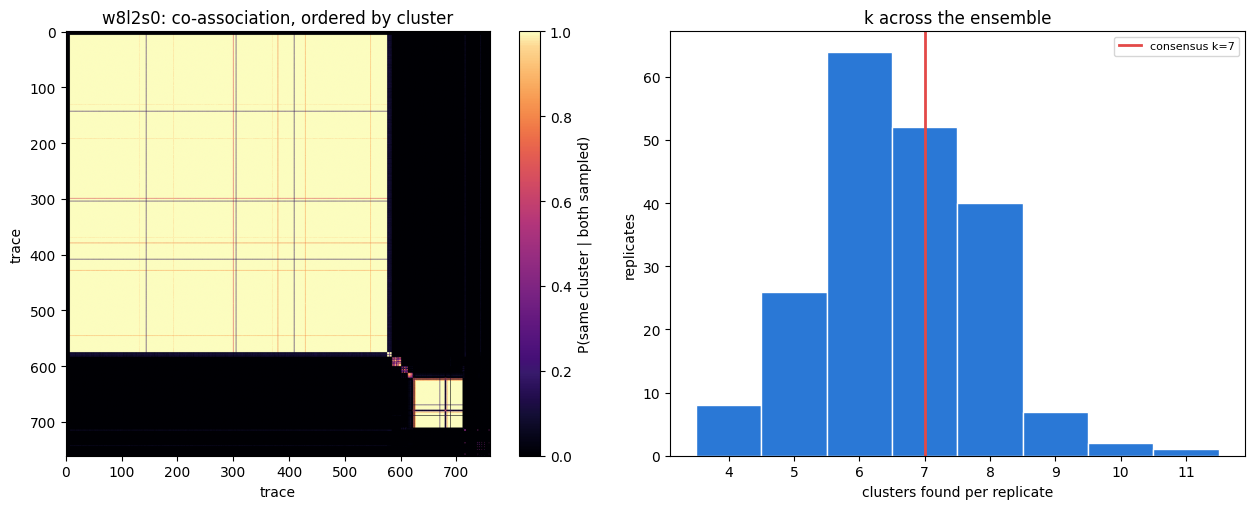

In [10]:
if EXAMPLE:
    from analysis.stability import resample_labels, coassociation

    d = json.loads((CLUSTERS_DIR / f"{EXAMPLE}_clusters.json").read_text())
    params = d["params"]
    dist = np.load(OUTPUT_DATA_DIR / "frechet" / f"{EXAMPLE}.npy")
    reps = resample_labels(dist, min_cluster_size=params["min_cluster_size"],
                            min_samples=params["min_samples"],
                            epsilon=params["cluster_selection_epsilon"],
                            B=params["bootstraps"], frac=params["frac"],
                            seed=params["seed"])
    C = coassociation(len(dist), reps)

    # Order by consensus cluster so the block structure is legible; noise last.
    labels = np.array(d["labels"])
    order = np.argsort([(1e6 if l == -1 else l) for l in labels], kind="stable")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    im = axes[0].imshow(C[np.ix_(order, order)], cmap=STABILITY_CMAP, vmin=0, vmax=1)
    axes[0].set_title(f"{EXAMPLE}: co-association, ordered by cluster")
    axes[0].set_xlabel("trace"); axes[0].set_ylabel("trace")
    fig.colorbar(im, ax=axes[0], label="P(same cluster | both sampled)")

    ks = [len({int(l) for l in lab.tolist()} - {-1}) for _, lab in reps]
    axes[1].hist(ks, bins=range(min(ks), max(ks) + 2), color="#2a78d6",
                 edgecolor="white", align="left")
    axes[1].axvline(len({l for l in labels if l != -1}), color="#e34948", lw=2,
                    label=f"consensus k={len({l for l in labels if l != -1})}")
    axes[1].set_xlabel("clusters found per replicate")
    axes[1].set_ylabel("replicates")
    axes[1].set_title("k across the ensemble")
    axes[1].legend(fontsize=8)

    fig.tight_layout()
    fig.savefig(OUTPUT_DATA_DIR / "clusters" / f"figure_stability_{EXAMPLE}.png", dpi=150,
                bbox_inches="tight")
    plt.show()

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w8l2s0_by_stability.png


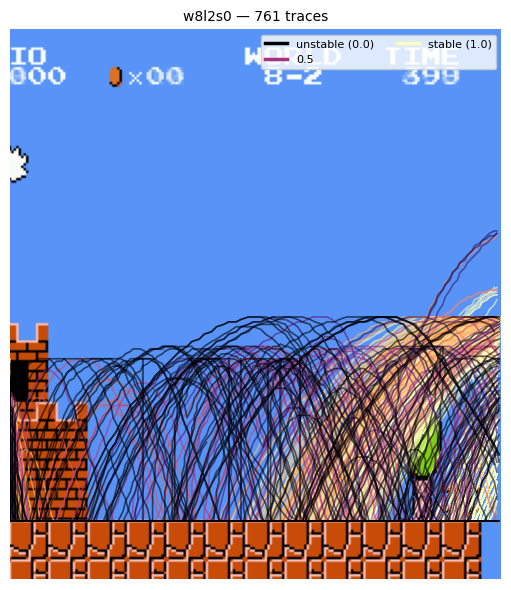

In [11]:
# The numbers against the trajectories: dark traces are the ones their cluster-mates
# rarely agreed with. Drawn on the scene background when one exists.
if EXAMPLE:
    plot_scene_clusters(EXAMPLE, SOURCE_DATA_DIR, OUTPUT_DATA_DIR,
                        color_by="stability",
                        background_dir=default_background_dir(SOURCE_DATA_DIR))

## 4. Resampling scheme — subagging vs Breiman bootstrap

The default is **subagging**: draw `frac * n` points *without* replacement. Classical
bagging is a **bootstrap**: draw `n` points *with* replacement, leaving ~63% unique.
Both are implemented (`scheme=` on `run-clustering`); this section runs the corpus
under each at identical parameters, `B` and seed, so the only difference is the draw.

In [12]:
cmp_path = STABILITY_DIR / "scheme_comparison.json"
if not cmp_path.exists():
    print("No scheme_comparison.json — run `invoke run-scheme-comparison`. Skipping section 4.")
    cmp_rows = []
else:
    cmp = json.loads(cmp_path.read_text())
    # Scene IDs only; the Fréchet cache also holds per-category matrices.
    cmp_rows = [r for r in cmp["rows"] if re.fullmatch(r"w\d+l\d+s\d+", r["scene"])]
    print(f"{len(cmp_rows)} scenes, params {cmp['params']}")

308 scenes, params {'min_cluster_size': 5, 'cluster_selection_epsilon': 20.0, 'bootstraps': 200, 'frac': 0.8, 'seed': 0, 'consensus_epsilon': 0.4}


/tmp/ipykernel_88369/4133114626.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([cdf.subagging_ksd, cdf.bootstrap_ksd], labels=["subagging", "bootstrap"],


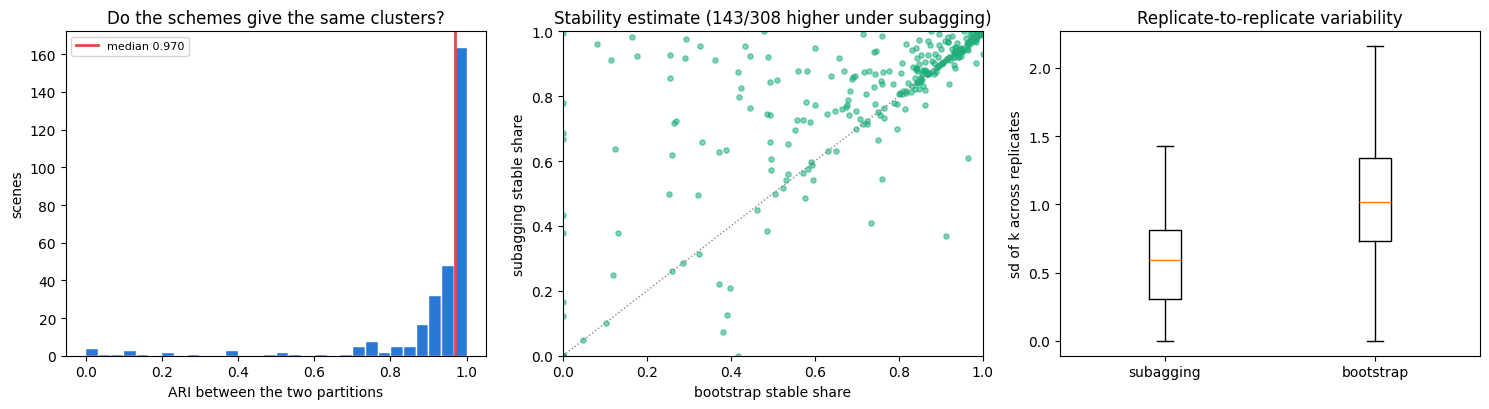

,subagging,bootstrap
median k,4.000,4.000
median stable share,0.877,0.838
trace-weighted stable share,0.816,0.739
median noise,0.074,0.070
mean replicate k sd,0.609,1.099
scenes >= 80%,209.000,170.000
scenes < 60%,49.000,89.000


In [13]:
if cmp_rows:
    cdf = pd.DataFrame([{
        "scene": r["scene"], "n": r["n"], "ari": r["ari"],
        **{f"{s}_{m}": r[s][m] for s in ("subagging", "bootstrap")
           for m in ("k", "stable_share", "noise_frac")},
        **{f"{s}_ksd": r[s]["k_replicates"]["sd"] for s in ("subagging", "bootstrap")},
    } for r in cmp_rows])

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

    # Do the two schemes even disagree about the clustering? (mostly not)
    axes[0].hist(cdf.ari, bins=30, color="#2a78d6", edgecolor="white")
    axes[0].axvline(cdf.ari.median(), color="#e34948", lw=2,
                    label=f"median {cdf.ari.median():.3f}")
    axes[0].set_xlabel("ARI between the two partitions")
    axes[0].set_ylabel("scenes")
    axes[0].set_title("Do the schemes give the same clusters?")
    axes[0].legend(fontsize=8)

    # They agree on the partition but not on how confident to be about it.
    lim = [0, 1]
    axes[1].scatter(cdf.bootstrap_stable_share, cdf.subagging_stable_share,
                    s=14, alpha=0.55, color="#1baf7a")
    axes[1].plot(lim, lim, ls=":", color="#898781", lw=1)
    axes[1].set_xlim(lim); axes[1].set_ylim(lim)
    axes[1].set_xlabel("bootstrap stable share")
    axes[1].set_ylabel("subagging stable share")
    axes[1].set_title(f"Stability estimate ({(cdf.subagging_stable_share > cdf.bootstrap_stable_share).sum()}"
                      f"/{len(cdf)} higher under subagging)")

    # The mechanism: bootstrap replicates are noisier, because ~37% of points are
    # missing from each one and HDBSCAN fragments what is left.
    axes[2].boxplot([cdf.subagging_ksd, cdf.bootstrap_ksd], labels=["subagging", "bootstrap"],
                    showfliers=False)
    axes[2].set_ylabel("sd of k across replicates")
    axes[2].set_title("Replicate-to-replicate variability")

    fig.tight_layout()
    fig.savefig(OUTPUT_DATA_DIR / "clusters" / "figure_stability_scheme.png", dpi=150,
                bbox_inches="tight")
    plt.show()

    summary = pd.DataFrame({
        s: {"median k": cdf[f"{s}_k"].median(),
            "median stable share": cdf[f"{s}_stable_share"].median(),
            "trace-weighted stable share": (cdf[f"{s}_stable_share"] * cdf.n).sum() / cdf.n.sum(),
            "median noise": cdf[f"{s}_noise_frac"].median(),
            "mean replicate k sd": cdf[f"{s}_ksd"].mean(),
            "scenes >= 80%": (cdf[f"{s}_stable_share"] >= 0.8).sum(),
            "scenes < 60%": (cdf[f"{s}_stable_share"] < 0.6).sum()}
        for s in ("subagging", "bootstrap")})
    display(summary.round(3))

Read together: the two schemes **agree about the clustering** (median ARI ~0.97) but not
about how much to trust it. The bootstrap's replicates are roughly twice as variable,
because each holds only ~63% unique points, so it reports lower stability for the same
partition. That is a property of the estimator, not of the data — which is why subagging
is the default here. Either can be run: `invoke run-clustering --scheme bootstrap`.